In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

%matplotlib inline

In [3]:
plt.rcParams["figure.figsize"] = (12,9)

# Read the data

In [4]:
wine_data = load_wine()

wine_df = pd.DataFrame(
    data=wine_data.data,
    columns=wine_data.feature_names
)

wine_df['target'] = wine_data.target

wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


C:\Users\Anwoy\AppData\Roaming\Python\Python312\site-packages\seaborn\categorical.py:3399: UserWarning: 8.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


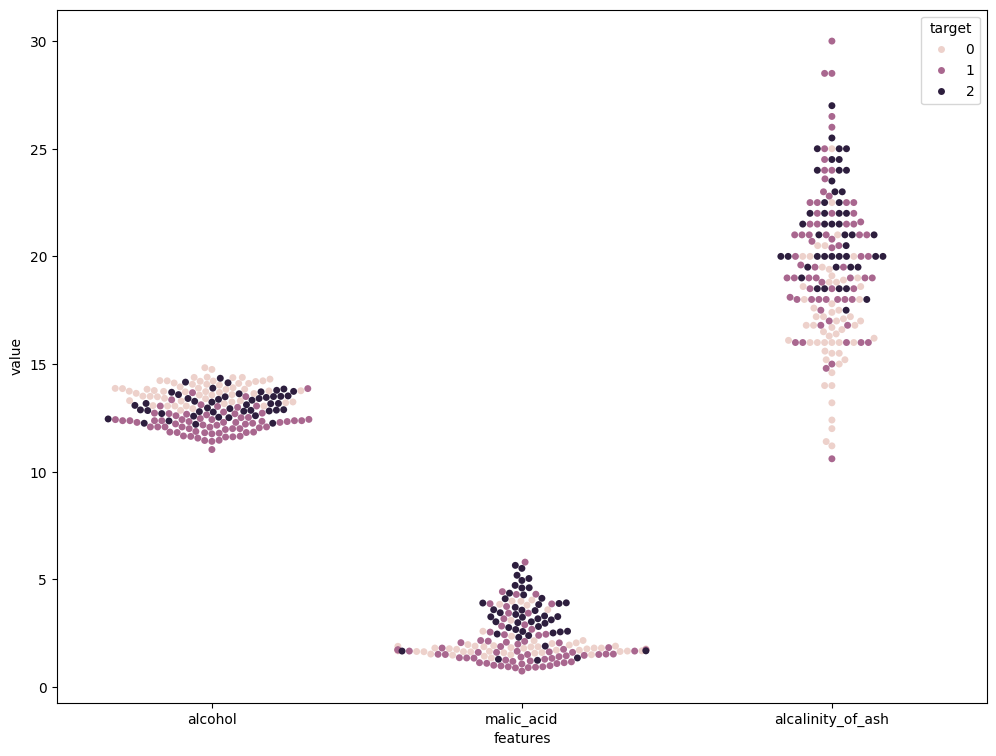

In [5]:
from seaborn import swarmplot

data_to_plot = pd.melt(wine_df[['alcohol', 'malic_acid', 'alcalinity_of_ash', 'target']],
                       id_vars='target',
                       var_name='features',
                       value_name='value')

swarmplot(data=data_to_plot, x='features', y='value', hue='target');

In [6]:
wine_df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

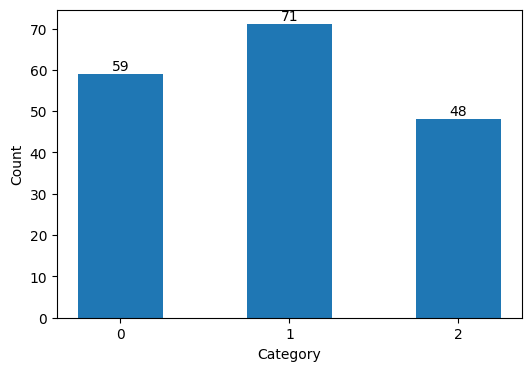

In [7]:
plt.figure(figsize= (6,4))

x = [0, 1, 2]
y = [59, 71, 48]

plt.bar(x,y, width = 0.5)
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks([0,1,2])

for index, value in enumerate(y):
    plt.text(x = int(index), y = int(value)+1, s = str(value), ha = 'center')
plt.show()

# Train test split

In [8]:
from sklearn.model_selection import train_test_split

X = wine_df.drop(['target'], axis=1)
y = wine_df['target']

X_train, X_test, y_train, y_test = train_test_split(X,
                                                   y,
                                                   test_size=0.3,
                                                   shuffle=True,
                                                   stratify=y,
                                                   random_state=42)

# Baseline model: Gradient Boosting Classifier with all features

In [9]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score

# Initialize classifier
gbc = GradientBoostingClassifier(max_depth=5, random_state=42)

# Train classifier using all features
gbc.fit(X_train, y_train)

# Make predictions
preds = gbc.predict(X_test)

# Evaluate the model using the F1-score
f1_score_all = round(f1_score(y_test, preds, average='weighted'), 3)

print(f1_score_all)

0.908


# Feature selection techniques

## Variance threshold

In [10]:
X_train_v1, X_test_v1, y_train_v1, y_test_v1 = X_train.copy(), X_test.copy(), y_train.copy(), y_test.copy()

In [11]:
X_train_v1.var(axis = 0)

alcohol                             0.658341
malic_acid                          1.123507
ash                                 0.072433
alcalinity_of_ash                  11.471279
magnesium                         232.071532
total_phenols                       0.393226
flavanoids                          0.912299
nonflavanoid_phenols                0.013873
proanthocyanins                     0.335108
color_intensity                     5.669722
hue                                 0.052891
od280/od315_of_diluted_wines        0.470021
proline                         94906.710923
dtype: float64

In [12]:
from sklearn.preprocessing import MinMaxScaler # one problem with min max scaler, it is sensative to outliers.

min_max_scaler = MinMaxScaler()

scaled_X_train_v1 = min_max_scaler.fit_transform(X_train_v1, y_train_v1)

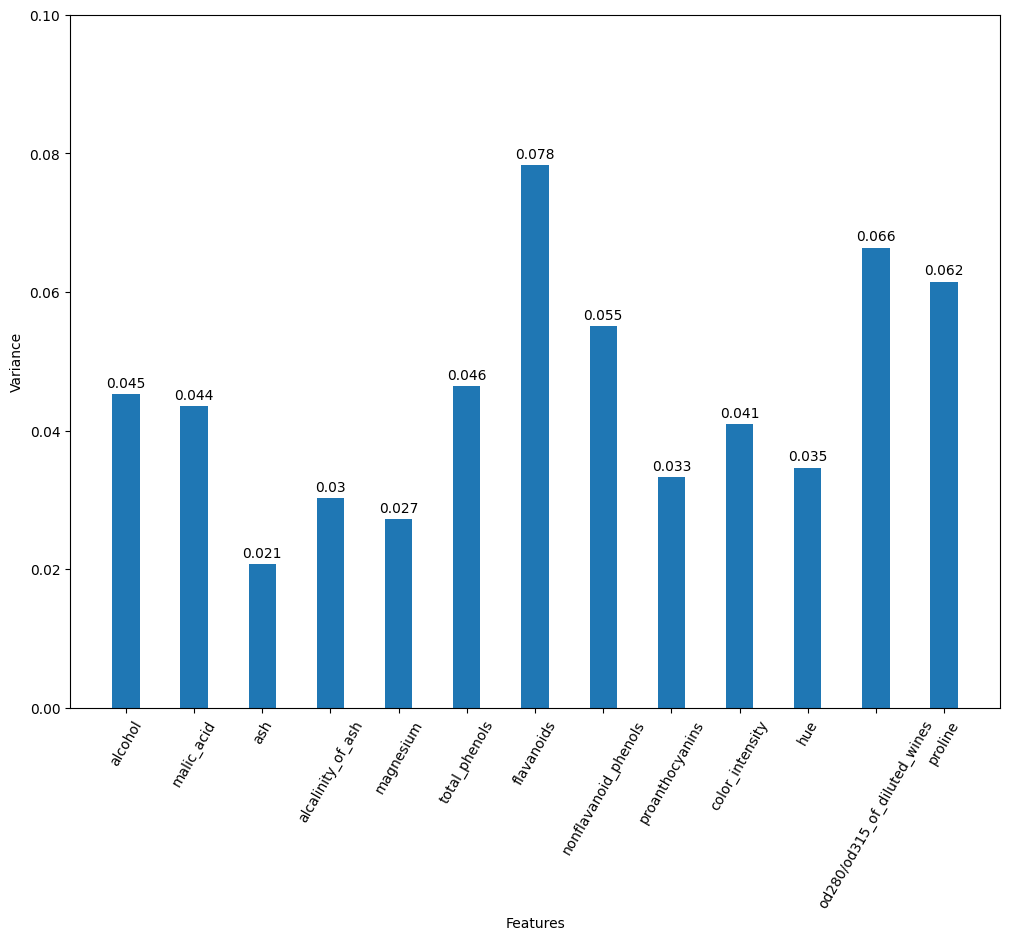

In [13]:
x = X.columns
y = scaled_X_train_v1.var(axis=0)

plt.bar(x, y, width=0.4)
plt.xlabel('Features')
plt.ylabel('Variance')
plt.xticks(rotation=60)
plt.ylim(0, 0.1)

for index, value in enumerate(y):
    plt.text(x=index, y=value+0.001, s=str(round(value, 3)), ha='center')



In [14]:
## we will select variables with variance greater than 0.03
sel_X_train_v1 = X_train_v1.drop(['ash', "alcalinity_of_ash", "magnesium"], axis=1)
sel_X_test_v1 = X_test_v1.drop(['ash', "alcalinity_of_ash", "magnesium"], axis= 1)

gbc.fit(sel_X_train_v1, y_train_v1)

y_pred = gbc.predict(sel_X_test_v1)

f1_score_var = round(f1_score(y_test_v1, y_pred, average= 'weighted'), 3)
f1_score_var

np.float64(0.963)

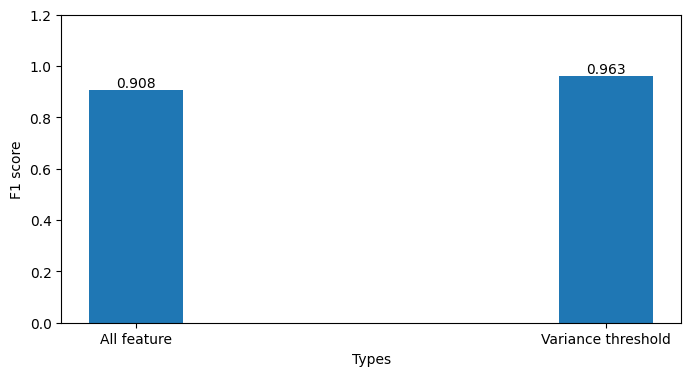

In [15]:
plt.figure(figsize= (8,4))

x = ["All feature", "Variance threshold"]
y = [f1_score_all, f1_score_var]

plt.bar(x,y, width = 0.2)
plt.xlabel('Types')
plt.ylabel('F1 score')
plt.ylim(0, 1.2)
for index, value in enumerate(y):
    plt.text(x=index, y=value+0.01, s=str(round(value,3)), ha='center')
    

## K-best features

In [16]:
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = X_train.copy(), X_test.copy(), y_train.copy(), y_test.copy()

In [17]:
X_train.shape

(124, 13)

In [21]:
y_train_v2

12     0
30     0
36     0
31     0
120    1
      ..
168    2
114    1
152    2
136    2
61     1
Name: target, Length: 124, dtype: int64

In [25]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

f1_score_k_best = []
for i in range(1,14):
    selector = SelectKBest(mutual_info_classif, k = i)
    selector.fit(X_train_v2, y_train_v2)

    X_train_v2_kbest = selector.transform(X_train_v2)
    X_test_v2_kbest = selector.transform(X_test_v2)
    gbc.fit(X_train_v2_kbest, y_train_v2)

    kbest_preds = gbc.predict(X_test_v2_kbest)
    f1_score_k = f1_score(y_test_v2, kbest_preds, average= 'weighted')
    f1_score_k_best.append(round(f1_score_k, 3))

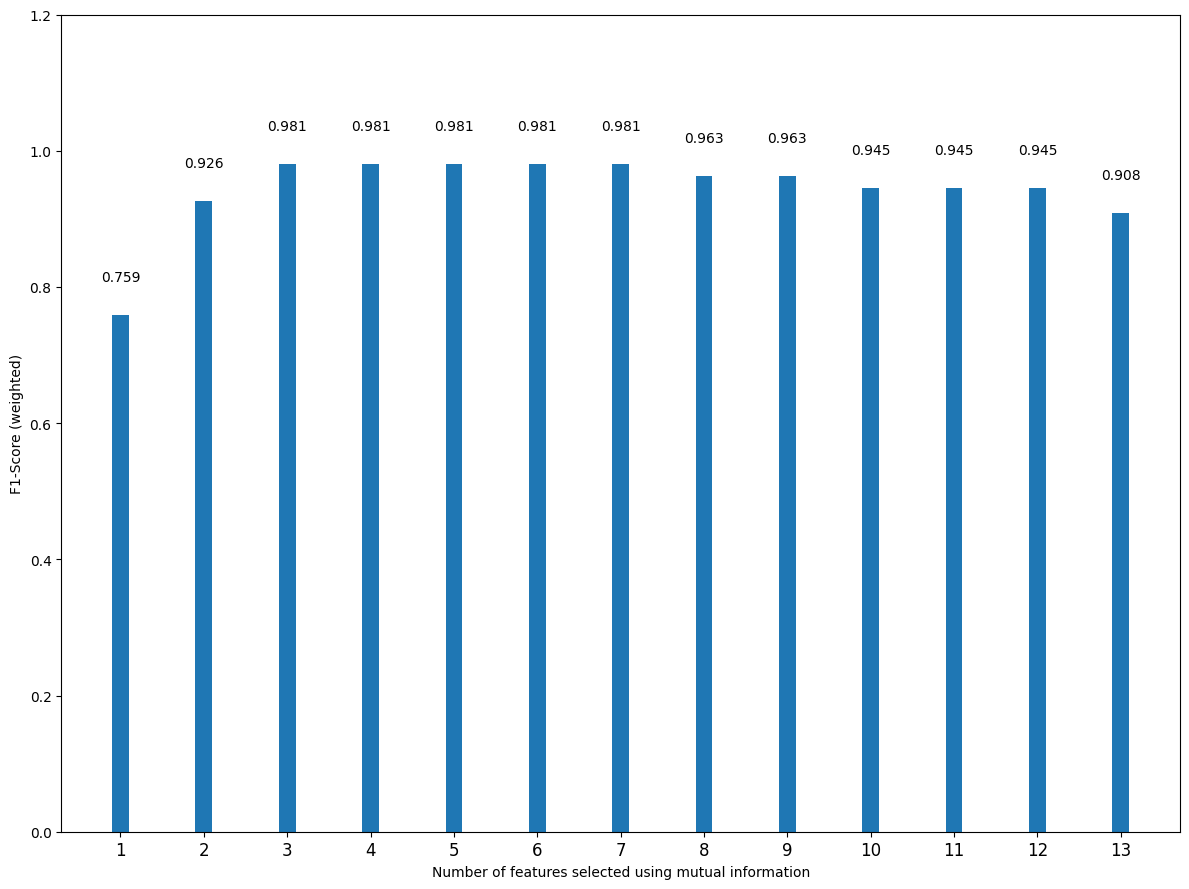

In [23]:
fig, ax = plt.subplots()

x = np.arange(1, 14)
y = f1_score_k_best

ax.bar(x, y, width=0.2)
ax.set_xlabel('Number of features selected using mutual information')
ax.set_ylabel('F1-Score (weighted)')
ax.set_ylim(0, 1.2)
ax.set_xticks(np.arange(1, 14))
ax.set_xticklabels(np.arange(1, 14), fontsize=12)

for i, v in enumerate(y):
    plt.text(x=i+1, y=v+0.05, s=str(v), ha='center')
    
plt.tight_layout()

In [73]:
selector = SelectKBest(mutual_info_classif, k=3)
selector.fit(X_train_v2, y_train_v2)

feature_mask = selector.get_support()
mask = X.columns[feature_mask]
mask

Index(['flavanoids', 'color_intensity', 'proline'], dtype='object')

In [74]:
X_train_v2_mask = X_train_v2[mask]
X_test_v2_mask = X_test_v2[mask]

gbc.fit(X_train_v2_mask, y_train)

pred = gbc.predict(X_test_v2_mask)
round(f1_score(y_test_v2, pred, average= 'weighted'),3)

np.float64(0.981)

## Recursive feature elimination (RFE)/ Wrapper method

In [75]:
X_train_v3, X_test_v3, y_train_v3, y_test_v3 = X_train.copy(), X_test.copy(), y_train.copy(), y_test.copy()

In [76]:
from sklearn.feature_selection import RFE

rfe_f1_score_list = []

for k in range(1, 14):
    RFE_selector = RFE(estimator=gbc, n_features_to_select=k, step=1)
    RFE_selector.fit(X_train_v3, y_train_v3)
    
    sel_X_train_v3 = RFE_selector.transform(X_train_v3)
    sel_X_test_v3 = RFE_selector.transform(X_test_v3)
    
    gbc.fit(sel_X_train_v3, y_train_v3)
    RFE_preds = gbc.predict(sel_X_test_v3)
    
    f1_score_rfe = round(f1_score(y_test_v3, RFE_preds, average='weighted'), 3)
    
    rfe_f1_score_list.append(f1_score_rfe)

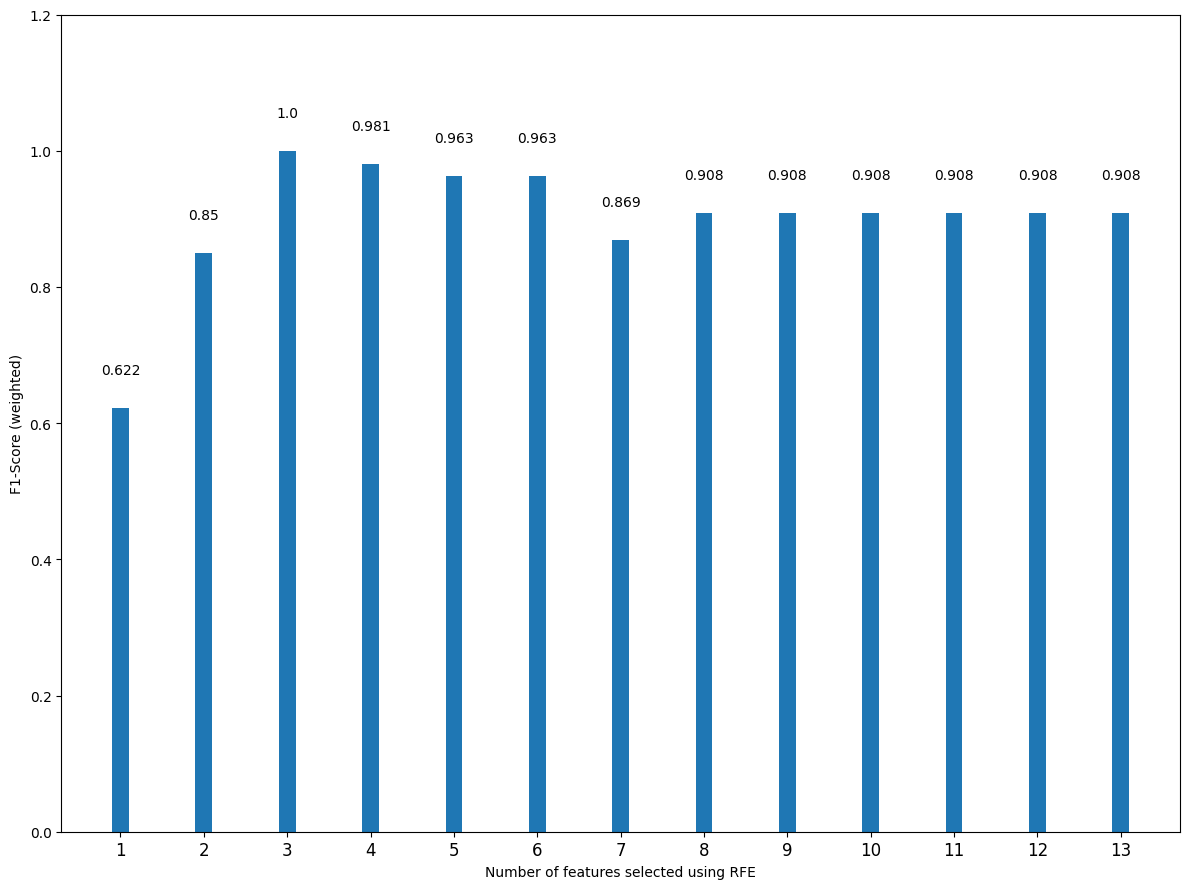

In [77]:
fig, ax = plt.subplots()

x = np.arange(1, 14)
y = rfe_f1_score_list

ax.bar(x, y, width=0.2)
ax.set_xlabel('Number of features selected using RFE')
ax.set_ylabel('F1-Score (weighted)')
ax.set_ylim(0, 1.2)
ax.set_xticks(np.arange(1, 14))
ax.set_xticklabels(np.arange(1, 14), fontsize=12)

for i, v in enumerate(y):
    plt.text(x=i+1, y=v+0.05, s=str(v), ha='center')
    
plt.tight_layout()

In [80]:
RFE_selector = RFE(estimator=gbc, n_features_to_select=3, step=10)
RFE_selector.fit(X_train_v3, y_train_v3)

selected_features_mask = RFE_selector.get_support()

selected_features = X_train_v3.columns[selected_features_mask]
selected_features

Index(['color_intensity', 'od280/od315_of_diluted_wines', 'proline'], dtype='object')

## Boruta

In [81]:

X_train_v4, X_test_v4, y_train_v4, y_test_v4 = X_train.copy(), X_test.copy(), y_train.copy(), y_test.copy()

In [89]:
from boruta import BorutaPy

boruta_selector = BorutaPy(gbc, random_state=42)

boruta_selector.fit(X_train_v4.values, y_train_v4.values.ravel())

sel_X_train_v4 = boruta_selector.transform(X_train_v4.values)
sel_X_test_v4 = boruta_selector.transform(X_test_v4.values)

gbc.fit(sel_X_train_v4, y_train_v4)

boruta_preds = gbc.predict(sel_X_test_v4)

boruta_f1_score = round(f1_score(y_test_v4, boruta_preds, average='weighted'), 3)
boruta_f1_score

np.float64(0.982)

In [87]:
selected_features_mask = boruta_selector.support_

selected_features = X_train_v4.columns[selected_features_mask]
selected_features

Index(['malic_acid', 'ash', 'magnesium', 'flavanoids', 'proanthocyanins',
       'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline'],
      dtype='object')

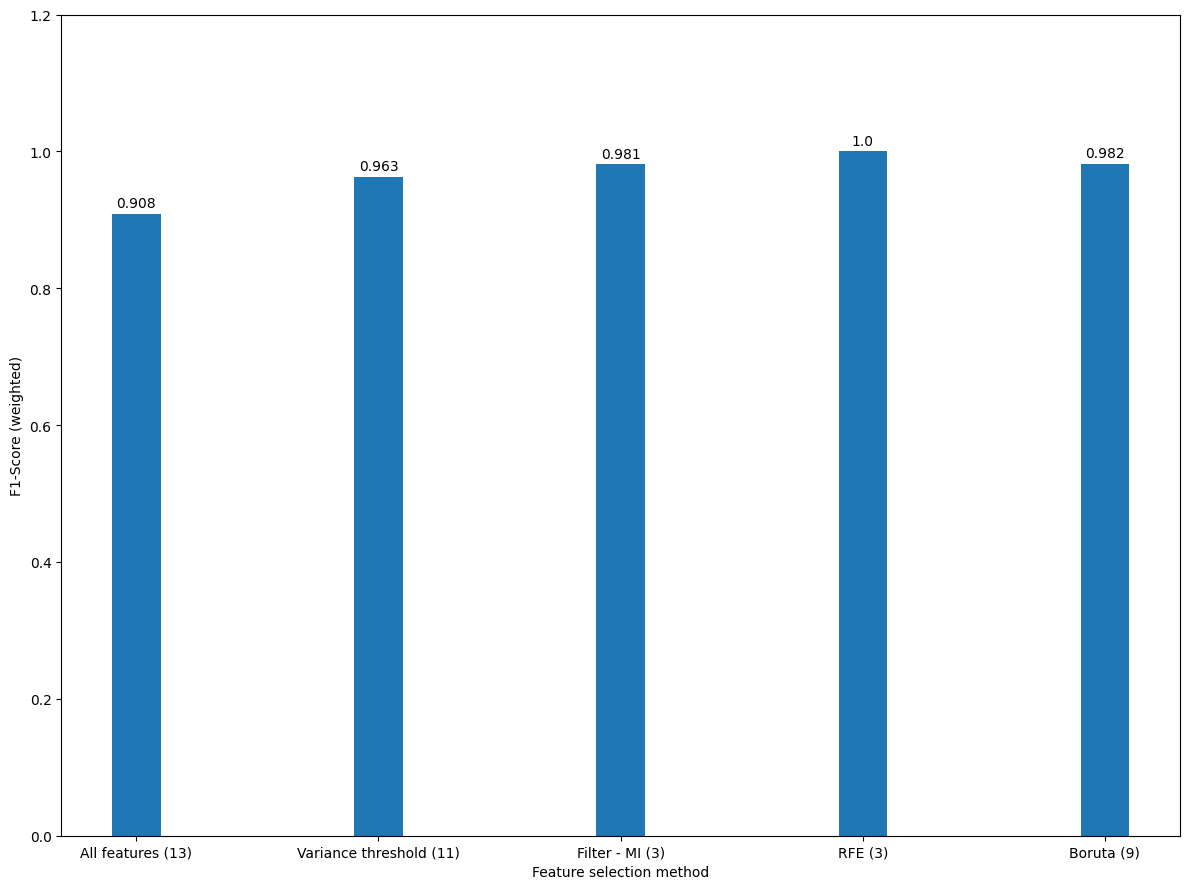

In [88]:
fig, ax = plt.subplots()

x = ['All features (13)', 'Variance threshold (11)', 'Filter - MI (3)', 'RFE (3)', 'Boruta (9)']
y = [f1_score_all, f1_score_var, 0.981, 1.0, boruta_f1_score]

ax.bar(x, y, width=0.2)
ax.set_xlabel('Feature selection method')
ax.set_ylabel('F1-Score (weighted)')
ax.set_ylim(0, 1.2)

for i, v in enumerate(y):
    plt.text(x=i, y=v+0.01, s=str(v), ha='center')
    
plt.tight_layout()